# Figure 5 — combined
This notebook assembles the combined Figure 5 from the source data and plotting logic.
Panel a and panels d–h are left blank as placeholders for externally edited images.


In [1]:
from __future__ import annotations

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure repo-local scripts/ and notebooks/ are importable (no src)
HERE = Path.cwd().resolve()
MODULE_PATHS = [
    HERE / 'scripts',
    HERE / 'notebooks',
    HERE / 'code_repository' / 'scripts',
    HERE / 'code_repository' / 'notebooks',
    HERE.parent / 'code_repository' / 'scripts',
    HERE.parent / 'code_repository' / 'notebooks',
]
for mp in reversed(MODULE_PATHS):
    if mp.exists() and str(mp) not in sys.path:
        sys.path.insert(0, str(mp))

from analysis.plot_style import apply_style, style_axes, save_figure, set_save_dir
from uncertainty.uncertainty_estimator import UncertaintyEstimator

apply_style()

ROOT = Path.cwd().resolve()
if (ROOT / 'Data').exists():
    PROJECT_ROOT = ROOT
elif (ROOT.parent / 'Data').exists():
    PROJECT_ROOT = ROOT.parent
elif (ROOT / 'code_repository' / 'Data').exists():
    PROJECT_ROOT = ROOT / 'code_repository'
elif (ROOT.parent / 'code_repository' / 'Data').exists():
    PROJECT_ROOT = ROOT.parent / 'code_repository'
else:
    PROJECT_ROOT = ROOT

FIGURE_ID = 'figure5'
SAVE_DIR = set_save_dir(PROJECT_ROOT, FIGURE_ID)


In [2]:
import math
import itertools

# ---- Panel b/c data: η-LOO uncertainty comparison ----
RESULTS_DIR_CANDIDATES = [
    PROJECT_ROOT / "analysis_exports/uncertainty_estimator",
    ROOT / "analysis_exports/uncertainty_estimator",
    ROOT / "code_repository/analysis_exports/uncertainty_estimator",
    ROOT.parent / "code_repository/analysis_exports/uncertainty_estimator",
]

RESULTS_DIR = None
for d in RESULTS_DIR_CANDIDATES:
    if (d / "eta_loo_overall_summary.csv").exists() and (d / "eta_loo_per_compound_metrics.csv").exists():
        RESULTS_DIR = d
        break

if RESULTS_DIR is None:
    tried = "\n".join(str(x) for x in RESULTS_DIR_CANDIDATES)
    raise FileNotFoundError(
        "Missing eta-LOO summary CSVs. Tried:\n" + tried
    )

OVERALL_CSV = RESULTS_DIR / "eta_loo_overall_summary.csv"
PER_COMP_CSV = RESULTS_DIR / "eta_loo_per_compound_metrics.csv"
# prefer Holm-named export, fallback to legacy filename
PAIRWISE_CSV = RESULTS_DIR / "eta_loo_pairwise_stats_Holm.csv"
if not PAIRWISE_CSV.exists():
    PAIRWISE_CSV = RESULTS_DIR / "eta_loo_pairwise_stats_BH.csv"

overall_summary = pd.read_csv(OVERALL_CSV)
per_comp_df = pd.read_csv(PER_COMP_CSV)

# Aggregate per-compound across LOO+LOSO (weight by #errors)
agg = (
    per_comp_df
      .assign(tp=lambda d: d["err_recall"] * d["n_err"])
      .groupby(["CompoundID", "Method"], as_index=False)
      .agg(tp_sum=("tp", "sum"), n_err_sum=("n_err", "sum"),
           coverage_mean=("coverage", "mean"), precision_mean=("precision", "mean"))
      .assign(err_recall=lambda d: np.where(d["n_err_sum"] > 0, d["tp_sum"] / d["n_err_sum"], np.nan))
)[["CompoundID", "Method", "err_recall", "coverage_mean", "precision_mean", "n_err_sum"]]

primary_metric = "err_recall"
wide = agg.pivot(index="CompoundID", columns="Method", values=primary_metric)
wide_clean = wide.dropna(axis=0, how="any")
methods = wide_clean.columns.tolist()
N = len(wide_clean)

# Pairwise stats vs best (use saved file if available)
if PAIRWISE_CSV.exists():
    stats_df = pd.read_csv(PAIRWISE_CSV)
else:
    # Friedman + Conover-style pairwise on ranks (normal approx), BH correction
    ranks = wide_clean.rank(axis=1, method="average", ascending=False)
    Rbar = ranks.mean(axis=0)
    k = len(methods)

    def norm_sf(z):
        return 0.5 * math.erfc(z / math.sqrt(2))

    pair_rows = []
    for i, j in itertools.combinations(range(k), 2):
        mi, mj = methods[i], methods[j]
        diff = Rbar[mi] - Rbar[mj]
        z = abs(diff) / math.sqrt(k * (k + 1) / (6 * N)) if N > 0 else np.nan
        p = 2 * norm_sf(abs(z)) if np.isfinite(z) else np.nan
        pair_rows.append({"MethodA": mi, "MethodB": mj, "z": z, "p_raw": p, "rank_diff": diff})
    pair_df = pd.DataFrame(pair_rows)

    # Holm correction (FWER)
    pvals = pair_df["p_raw"].values.astype(float)
    order = np.argsort(pvals)
    ranked = pvals[order]
    m = len(pvals)
    adj_ranked = np.empty(m, dtype=float)
    prev = 0.0
    for i, p in enumerate(ranked):
        val = (m - i) * p
        if val < prev:
            val = prev
        prev = val
        adj_ranked[i] = min(val, 1.0)
    p_adj = np.empty_like(pvals, dtype=float)
    p_adj[order] = adj_ranked
    pair_df["p_adj_Holm"] = p_adj
    pair_df["signif_Holm_5%"] = pair_df["p_adj_Holm"] <= 0.05
    # compatibility alias
    pair_df["p_adj_BH"] = pair_df["p_adj_Holm"]
    pair_df["signif_BH_5%"] = pair_df["signif_Holm_5%"]
    stats_df = pair_df


# ---- Plot helpers for panel b/c ----

def plot_eta_coverage_vs_recall(ax, overall_summary: pd.DataFrame) -> None:
    methods = list(overall_summary["Method"].astype(str))
    # Distinct palette (meta-model highlighted)
    base_palette = ["#1f77b4", "#2a9d8f", "#6baed6", "#74c476", "#f2c14e", "#f28e2b", "#e76f51", "#d1495b", "#8c6bb1"]
    color_map = {m: base_palette[i % len(base_palette)] for i, m in enumerate(methods)}
    for m in methods:
        if "meta-model" in m.lower():
            color_map[m] = "#0b2e6b"

    # Diagonal baseline
    ax.plot([0, 1], [0, 1], ls=(0, (3, 3)), color="0.5", lw=0.9, zorder=1)

    for _, row in overall_summary.iterrows():
        m = str(row["Method"])
        size = 26
        lw = 0.35
        ax.scatter(
            row["coverage"], row["err_recall"],
            s=size, color=color_map[m], alpha=0.85,
            edgecolor="black", linewidth=lw, zorder=3
        )

    ax.set_xlim(-0.02, 1.02)
    ax.set_ylim(-0.02, 1.02)
    ax.set_xlabel("Flag coverage")
    ax.set_ylabel("Error recall")
    ax.set_title("η-LOO uncertainty methods", pad=6)
    ax.set_xticks([0.0, 0.25, 0.5, 0.75, 1.0])
    ax.set_yticks([0.0, 0.25, 0.5, 0.75, 1.0])

    # Legend    
    handles = [
        plt.Line2D([0], [0], marker='o', linestyle='', color='none',
                   markerfacecolor=color_map[m], markeredgecolor='none',
                   markersize=5, label=m)
        for m in methods
    ]
    

    ax.legend(

        handles=handles,
        title="Method",
        frameon=False,
        loc="upper left",
        bbox_to_anchor=(1.02, 1.0),
        ncol=1,
        columnspacing=0.8,
        handletextpad=0.4,
        borderaxespad=0.0,
    )
    style_axes(ax)
    return color_map


def plot_eta_multiple_comparisons(ax, wide_clean: pd.DataFrame, stats_df: pd.DataFrame,
                                  primary_metric: str = "precision_mean") -> None:
    methods = wide_clean.columns.tolist()

    # Bootstrap mean + CI per method
    N_BOOT = 5000
    rng = np.random.default_rng(42)
    boot_rows = []
    for m in methods:
        vals = wide_clean[m].values
        mean = np.nanmean(vals)
        boots = []
        for _ in range(N_BOOT):
            s = rng.choice(vals, size=len(vals), replace=True)
            boots.append(np.nanmean(s))
        lo, hi = np.quantile(boots, [0.025, 0.975])
        boot_rows.append({"Method": m, "mean": mean, "ci_low": lo, "ci_high": hi})
    ci_df = pd.DataFrame(boot_rows)

    # Identify best method
    best_method = ci_df.sort_values("mean", ascending=False)["Method"].iloc[0]
    best_row = ci_df[ci_df["Method"] == best_method].iloc[0]

    # BH significance vs best
    sig_map = {}
    for _, r in stats_df.iterrows():
        if r.get("MethodA") == best_method and r.get("MethodB") in methods:
            sig_map[r["MethodB"]] = bool(r.get("p_adj_Holm", r.get("p_adj_BH", 1.0)) <= 0.05)
        if r.get("MethodB") == best_method and r.get("MethodA") in methods:
            sig_map[r["MethodA"]] = bool(r.get("p_adj_Holm", r.get("p_adj_BH", 1.0)) <= 0.05)

    def method_color(m):
        if m == best_method:
            return "#1f77b4"
        if sig_map.get(m, False):
            return "#c45c5c"
        return "#9e9e9e"

    ci_df["color"] = ci_df["Method"].apply(method_color)
    ci_df = ci_df.sort_values("mean")


    for _, row in ci_df.iterrows():
        ax.hlines(row["Method"], row["ci_low"], row["ci_high"],
                  colors=row["color"], linestyles="-", linewidth=0.8, zorder=2)
        ax.scatter(row["mean"], row["Method"],
                   s=26, color=row["color"], alpha=0.75,
                   edgecolor="black", linewidth=0.35, zorder=3)

    metric_label = "Error recall" if primary_metric == "err_recall" else primary_metric.replace('_', ' ')
    ax.set_xlabel(f"{metric_label} (mean ± 95% bootstrap CI)")
    ax.set_ylabel("")

    ax.yaxis.set_label_position("right")
    ax.yaxis.tick_right()
    ax.set_title("Multiple comparisons vs best method", pad=6)
    style_axes(ax)
    return color_map



In [3]:
# ---- Panel i/j/k/m data: external validation (with compound names) ----
compound_label_map = {
    "JH68": "Cystobactamid",
    "JH67": "Myxovirescin",
    "JH53": "Nitroxoline",
    "JH51": "Xanthocillin",
    "JH66": "Darobactin",
}

DISPLAY_ORDER = [
    'Fatty acid','Nitrofurans','Folic acid','Membrane',
    'RNA synth.','LPS synth.','DNA repl.','Cell wall','Protein syn.'
]

# Updated palette from Figure 2
COLORS = [
    "#264653", "#287271", "#2a9d8f", "#7fb48a",
    "#e9c46a", "#c6902e", "#f28e2b", "#e76f51", "#d1495b"
]

CANON_MAP = {
    'Fatty acid':      ['Fatty acid','Fatty acid synthesis'],
    'Nitrofurans':     ['Nitrofurans'],
    'Folic acid':      ['Folic acid','Folic acid metabolism','Folic acid biosynthesis'],
    'Membrane':        ['Membrane','Membrane disruption','Membrane integrity'],
    'RNA synth.':      ['RNA synth.','RNA Synthesis','RNA synthesis'],
    'LPS synth.':      ['LPS synth.','lipopolysaccharide synthesis','LPS synthesis'],
    'DNA repl.':       ['DNA repl.','DNA replication','DNA Replication'],
    'Cell wall':       ['Cell wall','Cell wall biosynthesis','Cell-wall biosynthesis'],
    'Protein syn.':    ['Protein syn.','Protein synthesis','Protein Synthesis'],
}

MOA_COLOR = {DISPLAY_ORDER[i]: COLORS[i] for i in range(len(DISPLAY_ORDER))}


def canonical_moa(moa: str) -> str:
    if moa is None:
        return "Unknown"
    s = str(moa).strip()
    for canon, variants in CANON_MAP.items():
        if s in variants:
            return canon
    return s


def moa_color(moa: str) -> str:
    canon = canonical_moa(moa)
    return MOA_COLOR.get(canon, "#888888")


PRED_ROOT_CANDIDATES = [
    PROJECT_ROOT / "predictions/Figure5_external_validation/Special_v1",
    ROOT / "predictions/Figure5_external_validation/Special_v1",
    ROOT / "code_repository/predictions/Figure5_external_validation/Special_v1",
    ROOT.parent / "code_repository/predictions/Figure5_external_validation/Special_v1",
    PROJECT_ROOT / "predictions/Figure5_external_validation/Special_semantic_prot_ecfp_cp_v1",
    ROOT / "predictions/Figure5_external_validation/Special_semantic_prot_ecfp_cp_v1",
    ROOT / "code_repository/predictions/Figure5_external_validation/Special_semantic_prot_ecfp_cp_v1",
    ROOT.parent / "code_repository/predictions/Figure5_external_validation/Special_semantic_prot_ecfp_cp_v1",
]
FIG5_EXTERNAL_PRED_ROOT = None
for d in PRED_ROOT_CANDIDATES:
    if (d / "pairwise_predictions.csv").exists() and (d / "pairwise_predictions_by_seed.csv").exists():
        FIG5_EXTERNAL_PRED_ROOT = d
        break
if FIG5_EXTERNAL_PRED_ROOT is None:
    tried = "\n".join(str(x) for x in PRED_ROOT_CANDIDATES)
    raise FileNotFoundError("Missing external prediction artifacts. Tried:\n" + tried)

FIG5_EXTERNAL_OUT_DIR = FIG5_EXTERNAL_PRED_ROOT / "uncertainty_meta_apply_semantic_allmod_fpr010"

# Resolve canonical meta-model artifacts (single source of truth)
META_DIR_CANDIDATES = [
    PROJECT_ROOT / "models/uncertainty_estimator",
    ROOT / "models/uncertainty_estimator",
    ROOT / "code_repository/models/uncertainty_estimator",
    ROOT.parent / "code_repository/models/uncertainty_estimator",
]

FIG5_META_DIR = None
for d in META_DIR_CANDIDATES:
    if (d / "meta_model.joblib").exists() and (d / "meta_artifact.json").exists():
        FIG5_META_DIR = d
        break

if FIG5_META_DIR is None:
    tried = "\n".join(str(x) for x in META_DIR_CANDIDATES)
    raise FileNotFoundError("Missing uncertainty_estimator artifacts. Tried:\n" + tried)

ue_all_modalities = UncertaintyEstimator(
    pred_root=str(FIG5_EXTERNAL_PRED_ROOT),
    meta_dir=str(FIG5_META_DIR),
    out_dir=str(FIG5_EXTERNAL_OUT_DIR),
    abs_min_score_floor=0.05,
    score_floor_factor=0.1,
    margin_floor=0.01,
)

out_df = ue_all_modalities.run()
meta_threshold = ue_all_modalities.meta_threshold

pairwise_csv = ue_all_modalities.PRED_ROOT / "pairwise_predictions.csv"
pairwise_df = pd.read_csv(pairwise_csv)


def plot_p_error_bar_ax(ax, df, threshold, compound_ids, label_map=None):
    sel = {str(c) for c in compound_ids}
    dff = df[df["CompoundID"].astype(str).isin(sel)].copy()
    if dff.empty:
        raise ValueError("No compounds left for p_error plot.")

    dff["CanonMoA"] = dff["PredictedMoA"].map(canonical_moa)
    dff["base_color"] = dff["CanonMoA"].map(moa_color)
    dff["color"] = np.where(dff["p_error"] >= threshold, "#aaaaaa", dff["base_color"])

    dff = dff.sort_values("p_error").reset_index(drop=True)
    labels = dff["CompoundID"].astype(str)
    if label_map:
        labels = labels.map(lambda c: label_map.get(c, c))

    x = np.arange(len(dff))
    ax.bar(x, dff["p_error"], color=dff["color"], edgecolor="black", linewidth=0.4)
    ax.axhline(threshold, color="red", linestyle="--", linewidth=1.0)

    # Mark floor overrides (if present)
    if "floor_applied" in dff.columns:
        for i, applied in enumerate(dff["floor_applied"]):
            if applied:
                ax.plot([i, i], [0, dff.loc[i, "p_error"]], linestyle=":", color="black", linewidth=0.6)

    ax.set_ylabel("Predicted error probability (p_error)")
    ax.set_xlabel("")
    ax.set_ylim(0, 1)
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=45, ha="right")

    # Legend
    handles = [
        plt.Line2D([0], [0], marker='o', linestyle='', color='none',
                   markerfacecolor=MOA_COLOR[m], markeredgecolor='none',
                   markersize=5, label=m)
        for m in DISPLAY_ORDER
    ]
    handles.append(
        plt.Line2D([0], [0], marker='o', linestyle='', color='none',
                   markerfacecolor="#aaaaaa", markeredgecolor='none',
                   markersize=5, label="Uncertain (p_error ≥ threshold)")
    )
    ax.legend(handles=handles, title="MoA", frameon=False, loc="upper left")
    style_axes(ax)


def plot_top3_moas_ax(ax, out_df, pairwise_df, compound_ids, label_map=None):
    sel = {str(c) for c in compound_ids}
    df = out_df[out_df["CompoundID"].astype(str).isin(sel)].copy()
    if df.empty:
        raise ValueError("No compounds left for top-3 MoA plot.")

    per_pair = pairwise_df.groupby(["CompoundID", "CandidateMoA"], as_index=False)["Score"].mean()
    comp_wide = per_pair.pivot(index="CompoundID", columns="CandidateMoA", values="Score")

    order = df.sort_values("p_error")["CompoundID"].astype(str).tolist()
    comp_wide = comp_wide.reindex(order)
    comp_wide.columns = [canonical_moa(c) for c in comp_wide.columns]

    rows = []
    for cid, row in comp_wide.iterrows():
        vals = row.dropna()
        if vals.empty:
            continue
        top3 = vals.sort_values(ascending=False).head(3)
        for rank, (moa, prob) in enumerate(top3.items()):
            rows.append({"CompoundID": cid, "MoA": moa, "Prob": float(prob), "Rank": rank})

    top3 = pd.DataFrame(rows)
    if top3.empty:
        raise RuntimeError("No rows for top-3 plot (after filtering / NaNs).")

    top3["color"] = top3["MoA"].map(moa_color)

    x_centers = np.arange(len(order))
    bar_width = 0.24
    offsets = {r: (r - 1) * bar_width for r in [0, 1, 2]}
    top3["x"] = top3.apply(
        lambda r: x_centers[order.index(r["CompoundID"])] + offsets[int(r["Rank"])],
        axis=1,
    )

    ax.bar(top3["x"], top3["Prob"], width=bar_width * 0.95,
           color=top3["color"], edgecolor="black", linewidth=0.4)

    labels = order
    if label_map:
        labels = [label_map.get(cid, cid) for cid in order]
    ax.set_xticks(x_centers)
    ax.set_xticklabels(labels, rotation=45, ha="right")
    ax.set_ylim(0, 1)
    ax.set_ylabel("Predicted probability per class")
    ax.set_xlabel("")

    handles = [
        plt.Line2D([0], [0], marker='o', linestyle='', color='none',
                   markerfacecolor=MOA_COLOR[m], markeredgecolor='none',
                   markersize=5, label=m)
        for m in DISPLAY_ORDER
    ]
    ax.legend(handles=handles, title="MoA", frameon=False, loc="upper left")
    style_axes(ax)


def plot_waterfall_ax(ax, ue, compound_id, label_map=None, max_pos=3, max_neg=3):
    """
    Minimal contribution view:
    top positive/negative features selected by mean, with all fold-level dots shown.
    """
    # Build risk-space input exactly as used for meta inference (before floor override)
    Z = ue.out.set_index("CompoundID")[ue.FEAT_ORDER].copy()
    for c in ue.negate_feats:
        if c in Z:
            Z[c] = -pd.to_numeric(Z[c], errors="coerce")
    for c in ue.FEAT_ORDER:
        if c not in Z:
            Z[c] = 0.0
    X_risk = Z[ue.FEAT_ORDER].apply(pd.to_numeric, errors="coerce").fillna(0.0)

    if compound_id not in X_risk.index:
        raise KeyError(f"CompoundID {compound_id} not found in uncertainty outputs.")

    x_vec = X_risk.loc[[compound_id], ue.FEAT_ORDER].values

    # Per-fold base-feature contributions (additive split of interaction terms)
    rows = []
    for fidx, cc in enumerate(ue.meta_clf.calibrated_classifiers_):
        base = getattr(cc, "base_estimator", None) or getattr(cc, "estimator", None)
        if base is None:
            for attr in ("classifier", "model", "pipeline"):
                base = getattr(cc, attr, None) or base
        if base is None:
            continue

        steps = dict(base.named_steps)
        scaler = steps.get("standardscaler")
        poly = steps.get("polynomialfeatures")
        lr = steps.get("logisticregression")
        if scaler is None or poly is None or lr is None:
            continue

        x_std = scaler.transform(x_vec)
        x_poly = poly.transform(x_std)
        term_contrib = x_poly[0] * lr.coef_.ravel()
        poly_names = poly.get_feature_names_out(ue.FEAT_ORDER)

        from collections import defaultdict
        acc = defaultdict(float)
        for val, pname in zip(term_contrib, poly_names):
            terms = [t.strip() for t in str(pname).split(" ")]
            bases = sorted({t.split("^")[0] for t in terms if t})
            bases = [b for b in bases if b in ue.FEAT_ORDER]
            if not bases:
                continue
            share = float(val) / float(len(bases))
            for b in bases:
                acc[b] += share

        for feat in ue.FEAT_ORDER:
            rows.append({"fold": fidx, "feature": feat, "contrib": float(acc.get(feat, 0.0))})

    if not rows:
        raise RuntimeError("Could not extract fold-wise contributions from meta model.")

    dfc = pd.DataFrame(rows)
    stats = dfc.groupby("feature", as_index=True)["contrib"].mean().to_frame("mean")

    # Select strongest mean effects, but show all fold-level dots.
    pos = stats[stats["mean"] > 0].sort_values("mean", ascending=False)
    neg = stats[stats["mean"] < 0].sort_values("mean", ascending=True)
    pos = pos.head(max_pos) if max_pos is not None else pos
    neg = neg.head(max_neg) if max_neg is not None else neg
    sel = pd.concat([pos, neg], axis=0)
    if sel.empty:
        sel = stats.sort_values("mean", ascending=False).head(6)

    # Rank-aware gradient: strongest + is darkest red, strongest - is darkest green.
    pos_palette = ["#8b0000", "#c53a3a", "#ef9a9a"]
    neg_palette = ["#1b7837", "#5aae61", "#a6dba0"]
    rank_map = {}
    for i, feat in enumerate(pos.index.tolist()):
        rank_map[feat] = ("pos", i + 1)
    for i, feat in enumerate(neg.index.tolist()):
        rank_map[feat] = ("neg", i + 1)

    def _color_for(feat):
        sign_rank = rank_map.get(feat)
        if sign_rank is None:
            return "#666666"
        sign, rank = sign_rank
        if sign == "pos":
            return pos_palette[min(rank - 1, len(pos_palette) - 1)]
        return neg_palette[min(rank - 1, len(neg_palette) - 1)]

    order = sel["mean"].sort_values(ascending=False).index.tolist()
    plot_folds = dfc[dfc["feature"].isin(order)].copy()
    y_map = {feat: i for i, feat in enumerate(order)}
    fold_ids = sorted(plot_folds["fold"].dropna().unique().tolist())
    if len(fold_ids) <= 1:
        fold_offsets = {fid: 0.0 for fid in fold_ids}
    else:
        offs = np.linspace(-0.16, 0.16, len(fold_ids))
        fold_offsets = {fid: float(off) for fid, off in zip(fold_ids, offs)}

    plot_folds["y"] = plot_folds["feature"].map(y_map) + plot_folds["fold"].map(fold_offsets).fillna(0.0)
    plot_folds["color"] = plot_folds["feature"].map(_color_for)

    ax.scatter(
        plot_folds["contrib"].values,
        plot_folds["y"].values,
        s=45,
        c=plot_folds["color"].values,
        edgecolor="none",
        alpha=0.95,
        zorder=3,
    )

    ax.axvline(0, color="black", linewidth=0.9)
    ax.set_yticks(np.arange(len(order)))
    ax.set_yticklabels(order)
    ax.invert_yaxis()
    ax.set_xlabel("Fold-wise feature contribution to error logit")

    row = ue.out.set_index("CompoundID").loc[compound_id]
    label = label_map.get(str(compound_id), str(compound_id)) if label_map else str(compound_id)
    title = f"{label} — MoA={row.get('PredictedMoA','?')}"
    ax.set_title(title)

    style_axes(ax)



/tmp/ipykernel_7802/667363024.py:97: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


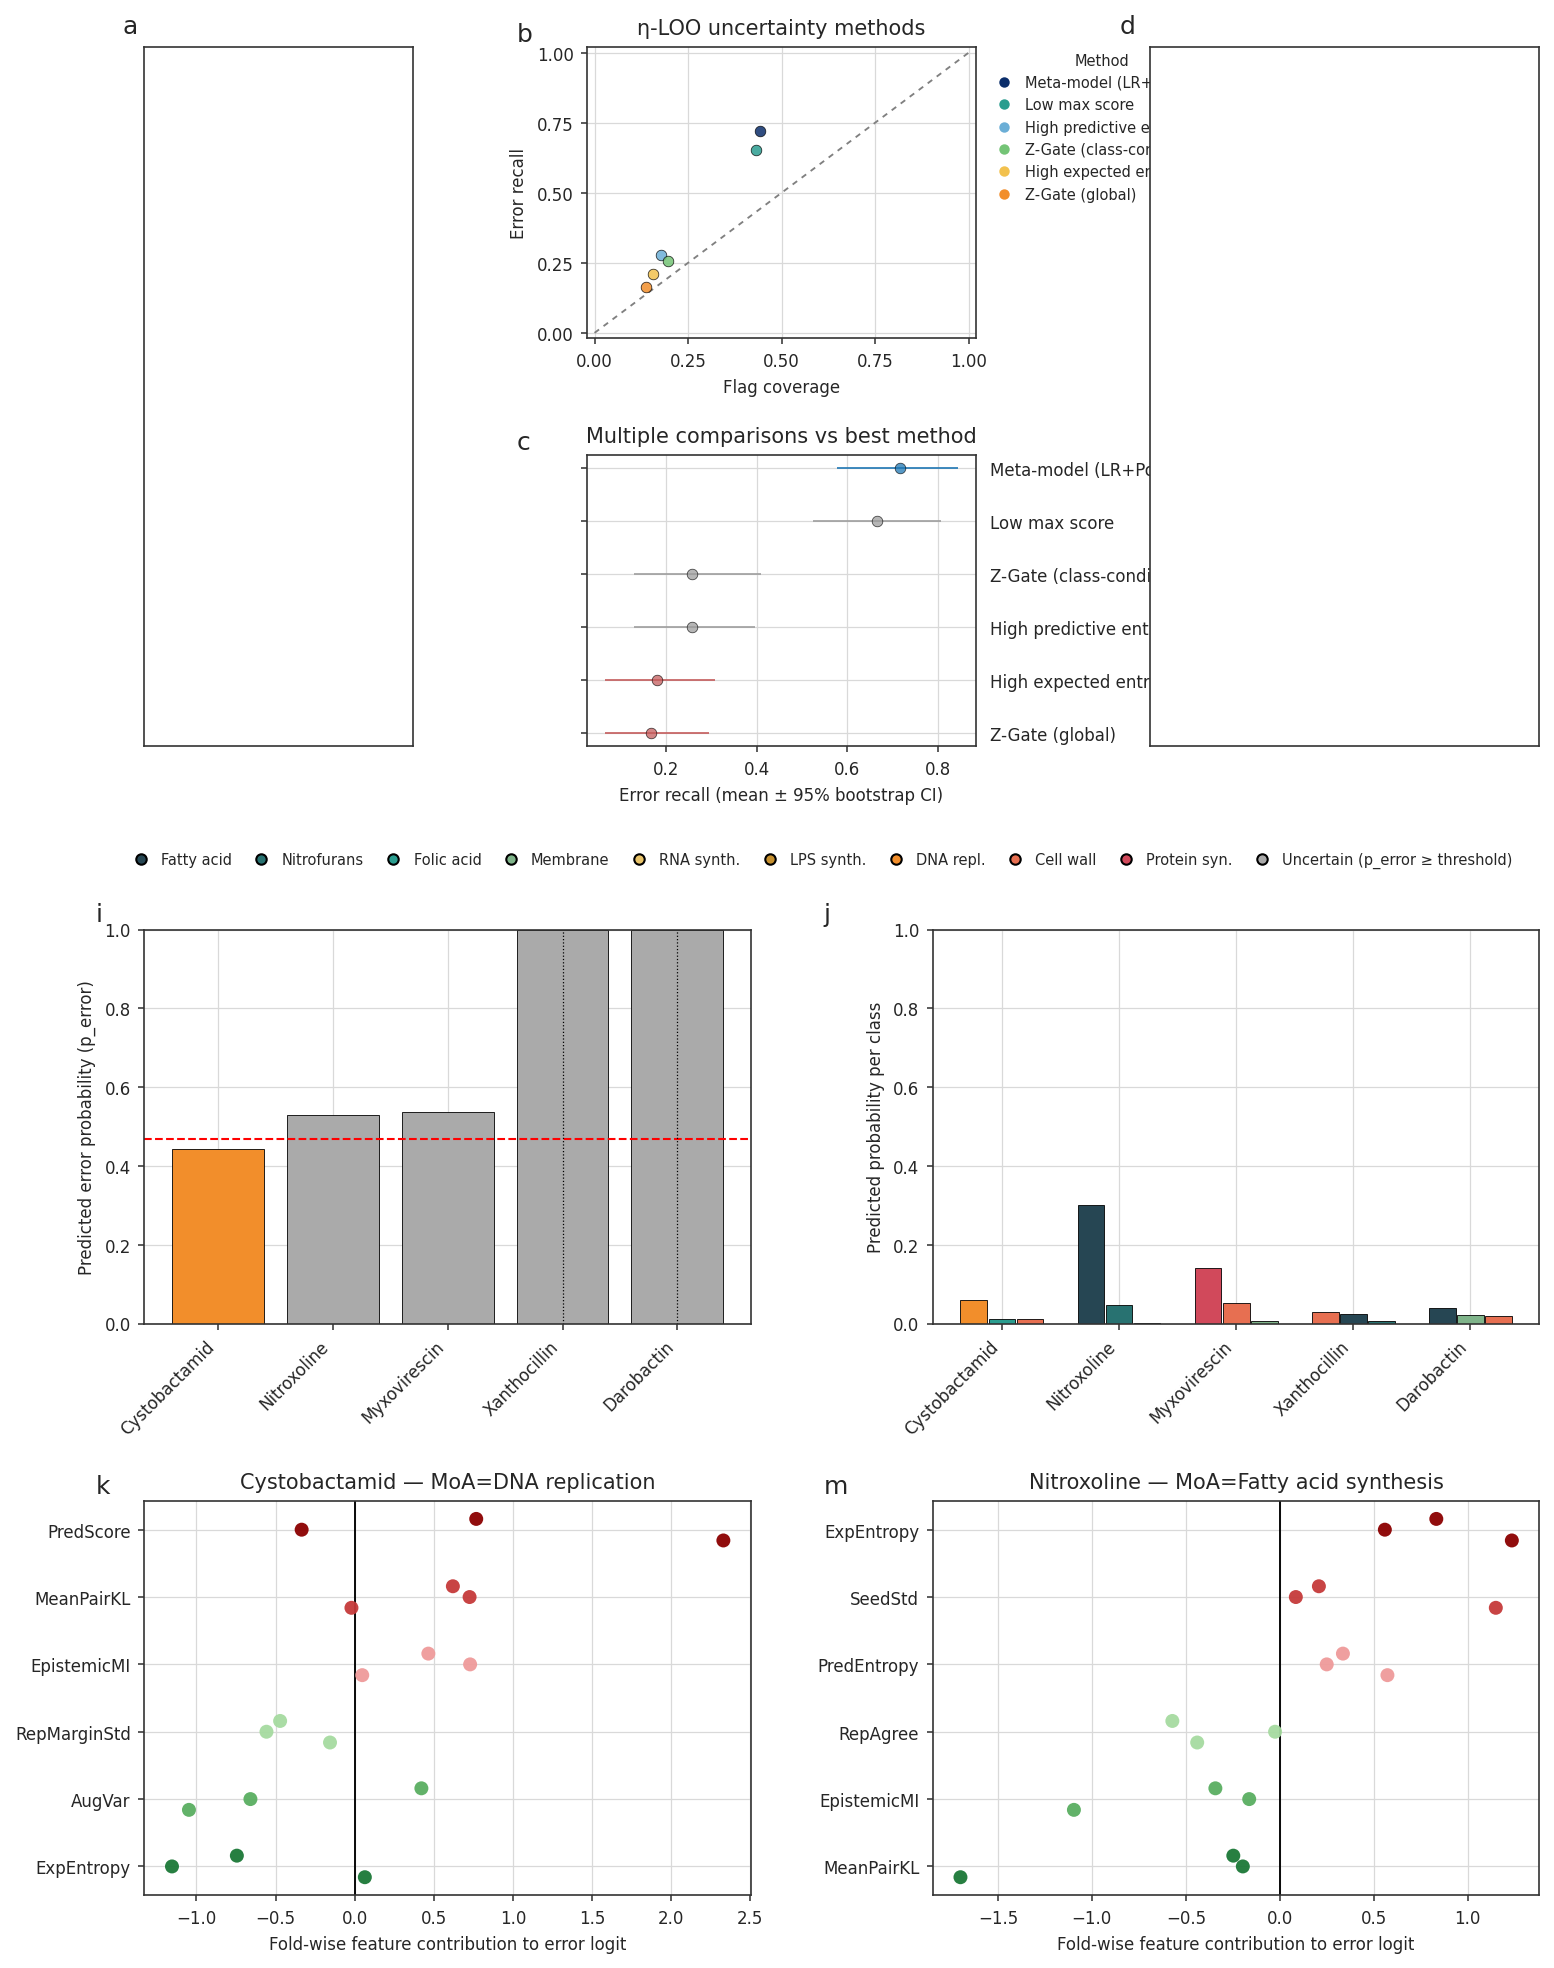

In [4]:
# ---- Build combined Figure 5 ----

fig = plt.figure(figsize=(12, 16))

outer = fig.add_gridspec(2, 1, height_ratios=[0.42, 0.58], hspace=0.22)

# Upper section: 3 horizontal blocks
upper = outer[0].subgridspec(1, 3, width_ratios=[1.0, 1.45, 1.45], wspace=0.5)

ax_a = fig.add_subplot(upper[0, 0])
mid = upper[0, 1].subgridspec(2, 1, hspace=0.4)
ax_b = fig.add_subplot(mid[0, 0])
ax_c = fig.add_subplot(mid[1, 0])
ax_right = fig.add_subplot(upper[0, 2])

# Lower section: 2x2 (barplots row, waterfalls row)
lower = outer[1].subgridspec(2, 2, wspace=0.3, hspace=0.45)
ax_i = fig.add_subplot(lower[0, 0])
ax_j = fig.add_subplot(lower[0, 1])
ax_k = fig.add_subplot(lower[1, 0])
ax_m = fig.add_subplot(lower[1, 1])


def placeholder(ax):
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(0.8)
        spine.set_color("0.4")
    ax.set_facecolor("white")


# Panel a placeholder
placeholder(ax_a)

# Right placeholder for panels d–h
placeholder(ax_right)

# Panel b/c
color_map = plot_eta_coverage_vs_recall(ax_b, overall_summary)
plot_eta_multiple_comparisons(ax_c, wide_clean, stats_df, primary_metric=primary_metric)



# Panels i/j
compound_ids = ["JH68", "JH51", "JH53", "JH66", "JH67"]
plot_p_error_bar_ax(ax_i, out_df, meta_threshold, compound_ids, label_map=compound_label_map)
plot_top3_moas_ax(ax_j, out_df, pairwise_df, compound_ids, label_map=compound_label_map)

# Use a shared external legend for i/j (MoA colors)
leg_i = ax_i.get_legend()
if leg_i is not None:
    leg_i.remove()
leg_j = ax_j.get_legend()
if leg_j is not None:
    leg_j.remove()

handles = [
    plt.Line2D([0], [0], marker='o', linestyle='',lw=0, color='none',
               markerfacecolor=MOA_COLOR[m],
               markersize=5, label=m)
    for m in DISPLAY_ORDER
]
handles.append(
    plt.Line2D([0], [0], marker='o', linestyle='',lw=0, color='none',
               markerfacecolor="#aaaaaa",
               markersize=5, label="Uncertain (p_error ≥ threshold)")
)

fig.legend(
    handles,
    [h.get_label() for h in handles],
    ncol=10,
    frameon=False,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.55),
    columnspacing=1.0,
    handletextpad=0.4,
)


# Panels k/m (waterfalls)
plot_waterfall_ax(ax_k, ue_all_modalities, "JH68", label_map=compound_label_map, max_pos=3, max_neg=3)
plot_waterfall_ax(ax_m, ue_all_modalities, "JH53", label_map=compound_label_map, max_pos=3, max_neg=3)

# Panel letters
ax_a.text(-0.08, 1.02, 'a', transform=ax_a.transAxes, fontsize=12)
ax_b.text(-0.18, 1.02, 'b', transform=ax_b.transAxes, fontsize=12)
ax_c.text(-0.18, 1.02, 'c', transform=ax_c.transAxes, fontsize=12)
ax_right.text(-0.08, 1.02, 'd', transform=ax_right.transAxes, fontsize=12)
ax_i.text(-0.08, 1.02, 'i', transform=ax_i.transAxes, fontsize=12)
ax_j.text(-0.18, 1.02, 'j', transform=ax_j.transAxes, fontsize=12)
ax_k.text(-0.08, 1.02, 'k', transform=ax_k.transAxes, fontsize=12)
ax_m.text(-0.18, 1.02, 'm', transform=ax_m.transAxes, fontsize=12)

fig.tight_layout()
save_figure(fig, 'figure5_combined')
plt.show()




